# DDPM Face Generation — FFHQ (100 Images)

**Complete pipeline:** Google Drive dataset loading → preprocessing → Dataset/DataLoader → forward diffusion → U-Net → 10-epoch training → checkpoint → reverse diffusion → generated samples.

- Dataset: exactly 100 FFHQ images from `100 images.zip`
- Resolution: 64×64 RGB
- Diffusion steps: 1000
- Training: 10 epochs
- Outputs: displayed in this notebook and saved to Google Drive for GitHub submission

> Note: Forward diffusion adds Gaussian noise (it does not apply a conventional blur filter). Reverse diffusion uses the trained U-Net to denoise random noise. With only 100 training images and a compact model, generated faces may be noisy or blurry.

## 1. Imports, reproducibility and device

In [29]:
import os
import zipfile
import shutil
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 2. Mount Google Drive and extract `100 images.zip`

In [30]:
from google.colab import drive
drive.mount("/content/drive")

# ZIP is directly inside MyDrive with this exact filename.
ZIP_PATH = Path("/content/drive/MyDrive/100 images.zip")

RAW_DIR = Path("/content/ffhq_raw")
IMAGE_DIR = Path("/content/ffhq_64")

PROJECT_DIR = Path("/content/drive/MyDrive/DDPM_Project")
RESULTS_DIR = PROJECT_DIR / "results"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP not found at: {ZIP_PATH}\n"
        "Check that '100 images.zip' is directly inside Google Drive > MyDrive."
    )

print("ZIP found:", ZIP_PATH)

# Re-extract cleanly so old files cannot accidentally increase the image count.
if RAW_DIR.exists():
    shutil.rmtree(RAW_DIR)
RAW_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(RAW_DIR)

extensions = {".jpg", ".jpeg", ".png", ".webp"}
all_image_paths = sorted(
    p for p in RAW_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Images found in ZIP:", len(all_image_paths))
if len(all_image_paths) < 100:
    raise ValueError(f"Expected at least 100 images, found {len(all_image_paths)}.")

# Use exactly 100 images, even if the ZIP contains extra image files.
image_paths = all_image_paths[:100]
print("Images selected:", len(image_paths))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP found: /content/drive/MyDrive/100 images.zip
Images found in ZIP: 100
Images selected: 100


## 3. Preprocess images to 64×64 RGB

Processed images: 100


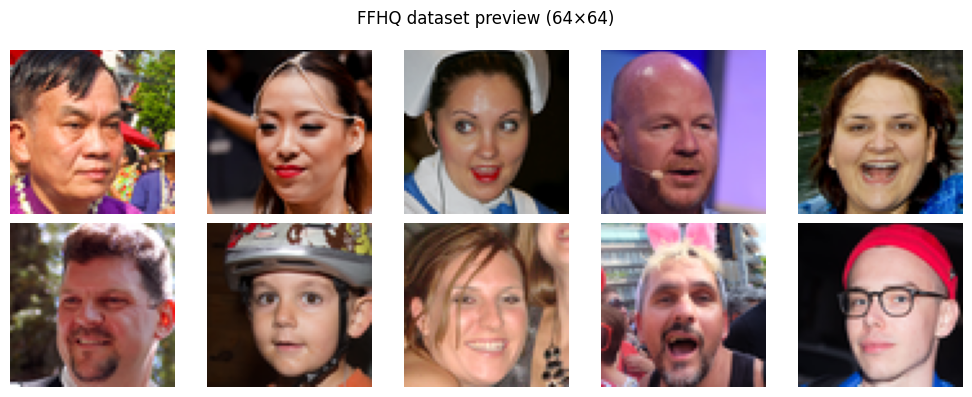

Saved: /content/drive/MyDrive/DDPM_Project/results/dataset_preview.png


In [31]:
if IMAGE_DIR.exists():
    shutil.rmtree(IMAGE_DIR)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

for i, path in enumerate(image_paths):
    with Image.open(path) as img:
        img = img.convert("RGB").resize((64, 64), Image.Resampling.LANCZOS)
        img.save(IMAGE_DIR / f"face_{i:03d}.png")

processed_paths = sorted(IMAGE_DIR.glob("*.png"))
print("Processed images:", len(processed_paths))
assert len(processed_paths) == 100, "The processed dataset must contain exactly 100 images."

# Display a small preview of the processed dataset.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, path in zip(axes.flat, processed_paths[:10]):
    ax.imshow(Image.open(path))
    ax.axis("off")
plt.suptitle("FFHQ dataset preview (64×64)")
plt.tight_layout()
preview_path = RESULTS_DIR / "dataset_preview.png"
plt.savefig(preview_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", preview_path)

## 4. Dataset and DataLoader

`ToTensor()` converts pixel values to `[0,1]`. `Normalize((0.5,)*3, (0.5,)*3)` maps them to `[-1,1]`, which is the range used by this DDPM training pipeline.

In [32]:
class FFHQDataset(Dataset):
    def __init__(self, folder):
        self.paths = sorted(Path(folder).glob("*.png"))
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5,)*3, (0.5,)*3)
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            return self.transform(img.convert("RGB"))

dataset = FFHQDataset(IMAGE_DIR)
dataloader = DataLoader(
    dataset,
    batch_size=8,
    shuffle=True,
    drop_last=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

batch = next(iter(dataloader))
print("Dataset size:", len(dataset))
print("Batch shape:", batch.shape)
print("Pixel range:", batch.min().item(), "to", batch.max().item())

Dataset size: 100
Batch shape: torch.Size([8, 3, 64, 64])
Pixel range: -1.0 to 1.0


## 5. Forward diffusion schedule

We define `beta`, `alpha = 1-beta`, and cumulative `alpha_bar`. The `q_sample` function adds Gaussian noise to a clean image at a selected timestep:

\[
x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon
\]

where \(\epsilon\) is sampled from a standard normal distribution.

In [33]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

def q_sample(x0, t):
    noise = torch.randn_like(x0)
    alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)
    xt = torch.sqrt(alpha_bar_t) * x0 + torch.sqrt(1 - alpha_bar_t) * noise
    return xt, noise

x0 = next(iter(dataloader)).to(device)
t = torch.randint(0, T, (x0.shape[0],), device=device)
xt, noise = q_sample(x0, t)
print("x0:", x0.shape, "| xt:", xt.shape, "| noise:", noise.shape)
print("Final alpha_bar:", alpha_bars[-1].item())

x0: torch.Size([8, 3, 64, 64]) | xt: torch.Size([8, 3, 64, 64]) | noise: torch.Size([8, 3, 64, 64])
Final alpha_bar: 4.035830352222547e-05


## 6. Visualize forward diffusion (clean image → noisy image)

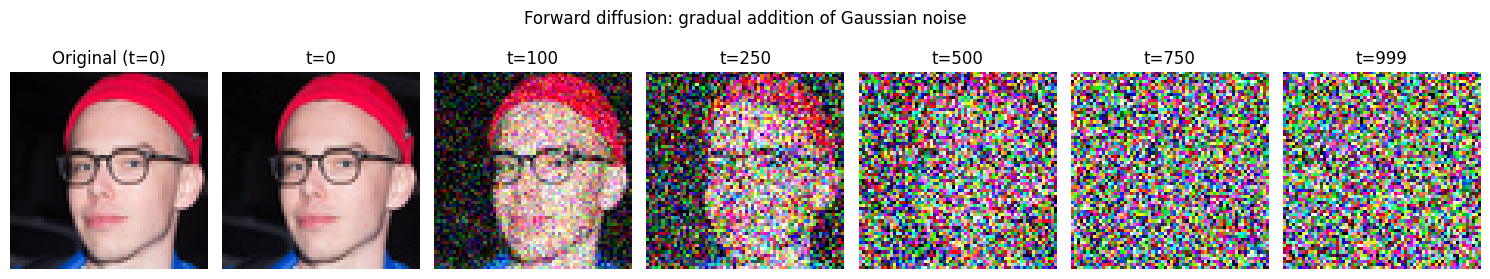

Saved: /content/drive/MyDrive/DDPM_Project/results/forward_diffusion_progression.png


In [34]:
# Show one clean image at increasing diffusion timesteps.
sample = next(iter(dataloader))[0:1].to(device)
timesteps_to_show = [0, 100, 250, 500, 750, 999]

fig, axes = plt.subplots(1, len(timesteps_to_show) + 1, figsize=(15, 3))
clean_img = ((sample[0].cpu() + 1) / 2).clamp(0, 1)
axes[0].imshow(clean_img.permute(1, 2, 0))
axes[0].set_title("Original (t=0)")
axes[0].axis("off")

for ax, step in zip(axes[1:], timesteps_to_show):
    t_batch = torch.tensor([step], device=device, dtype=torch.long)
    noisy, _ = q_sample(sample, t_batch)
    display_img = ((noisy[0].cpu() + 1) / 2).clamp(0, 1)
    ax.imshow(display_img.permute(1, 2, 0))
    ax.set_title(f"t={step}")
    ax.axis("off")

plt.suptitle("Forward diffusion: gradual addition of Gaussian noise")
plt.tight_layout()
forward_plot = RESULTS_DIR / "forward_diffusion_progression.png"
plt.savefig(forward_plot, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", forward_plot)

## 7. U-Net noise predictor
This compact U-Net receives a noisy RGB image and timestep, then predicts the Gaussian noise.

In [35]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU()
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, T=1000):
        super().__init__()
        self.encoder = ConvBlock(3, 32)
        self.downsample = nn.Conv2d(32, 64, 3, stride=2, padding=1)
        self.time_embedding = nn.Embedding(T, 32)
        self.time_projection = nn.Linear(32, 64)
        self.upsample = nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1)
        self.decoder = ConvBlock(64, 32)
        self.final_conv = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, x, t):
        skip = self.encoder(x)
        x = self.downsample(skip)
        t_emb = self.time_projection(self.time_embedding(t))
        x = x + t_emb[:, :, None, None]
        x = self.upsample(x)
        x = torch.cat([x, skip], dim=1)
        x = self.decoder(x)
        return self.final_conv(x)

model = UNet(T=T).to(device)
test_x = torch.randn(2, 3, 64, 64, device=device)
test_t = torch.randint(0, T, (2,), device=device)
print("Predicted noise shape:", model(test_x, test_t).shape)

Predicted noise shape: torch.Size([2, 3, 64, 64])


## 8. Training setup
The model learns to predict the Gaussian noise added to each clean image. Mean Squared Error (MSE) is minimized using Adam.

In [36]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0

    for x0 in loader:
        x0 = x0.to(device, non_blocking=True)
        t = torch.randint(0, T, (x0.shape[0],), device=device)
        xt, actual_noise = q_sample(x0, t)

        predicted_noise = model(xt, t)
        loss = criterion(predicted_noise, actual_noise)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

## 9. Train the model (10 epochs)
Run this cell once for a fresh training run. The loss plot is displayed and saved to Google Drive.

Epoch [1/10] loss: 0.997353
Epoch [2/10] loss: 0.991168
Epoch [3/10] loss: 0.971784
Epoch [4/10] loss: 0.944011
Epoch [5/10] loss: 0.890444
Epoch [6/10] loss: 0.841691
Epoch [7/10] loss: 0.784036
Epoch [8/10] loss: 0.705552
Epoch [9/10] loss: 0.602783
Epoch [10/10] loss: 0.513180


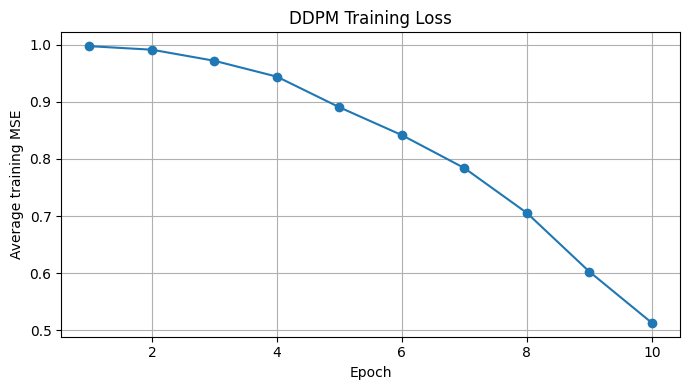

Saved: /content/drive/MyDrive/DDPM_Project/results/training_loss.png


In [37]:
NUM_EPOCHS = 10
loss_history = []

for epoch in range(NUM_EPOCHS):
    epoch_loss = train_one_epoch(model, dataloader, optimizer, criterion)
    loss_history.append(epoch_loss)
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}] loss: {epoch_loss:.6f}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average training MSE")
plt.title("DDPM Training Loss")
plt.grid(True)
plt.tight_layout()
loss_plot_path = RESULTS_DIR / "training_loss.png"
plt.savefig(loss_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", loss_plot_path)

## 10. Save model checkpoint to Google Drive

In [38]:
completed_epochs = len(loss_history)
checkpoint_path = CHECKPOINT_DIR / f"ddpm_epoch_{completed_epochs}.pth"

torch.save({
    "epoch": completed_epochs,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "loss_history": loss_history,
    "T": T
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)

Checkpoint saved: /content/drive/MyDrive/DDPM_Project/checkpoints/ddpm_epoch_10.pth


## 11. Reverse diffusion / image generation

The U-Net estimates the noise at each timestep. Starting from random Gaussian noise, the sampler iteratively removes the estimated noise using the DDPM reverse update. This is the generation stage of the project.

In [39]:
alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])
posterior_variance = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)

@torch.no_grad()
def generate_images(model, num_images=4):
    model.eval()
    x = torch.randn(num_images, 3, 64, 64, device=device)

    for step in reversed(range(T)):
        t = torch.full((num_images,), step, device=device, dtype=torch.long)

        beta_t = betas[t].view(-1, 1, 1, 1)
        alpha_t = alphas[t].view(-1, 1, 1, 1)
        alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)

        predicted_noise = model(x, t)
        mean = (
            x - beta_t / torch.sqrt(1 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_t)

        if step > 0:
            variance_t = posterior_variance[t].view(-1, 1, 1, 1)
            x = mean + torch.sqrt(variance_t) * torch.randn_like(x)
        else:
            x = mean

    return x.clamp(-1, 1)

## 12. Generate and display samples

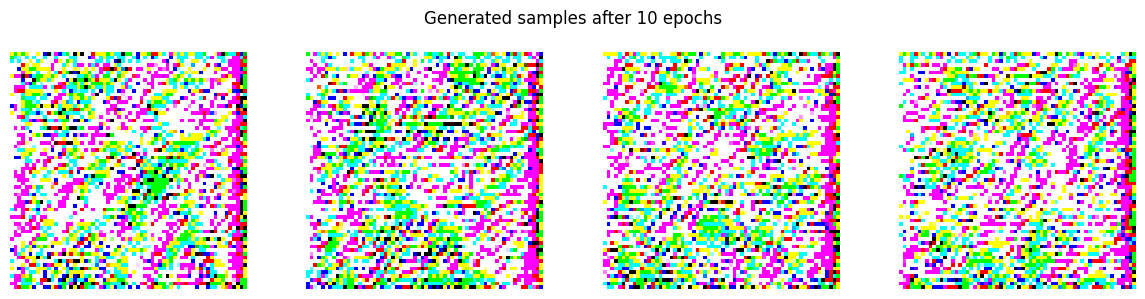

Generated samples saved: /content/drive/MyDrive/DDPM_Project/results/generated_samples.png


In [40]:
generated_images = generate_images(model, num_images=4)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    img = ((generated_images[i].cpu() + 1) / 2).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0))
    ax.axis("off")

plt.suptitle(f"Generated samples after {completed_epochs} epochs")
plt.tight_layout()
generated_plot_path = RESULTS_DIR / "generated_samples.png"
plt.savefig(generated_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Generated samples saved:", generated_plot_path)

## 13. Save final noisy sample and list submission outputs

The notebook keeps both intermediate forward-diffusion results and generated reverse-diffusion samples. All result images and the checkpoint are stored in `MyDrive/DDPM_Project/`.

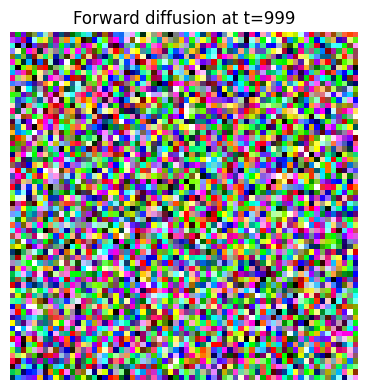


Project outputs:
README.txt - 416 bytes
dataset_preview.png - 154982 bytes
forward_diffusion_progression.png - 161047 bytes
forward_diffusion_t999.png - 32761 bytes
generated_samples.png - 41866 bytes
training_loss.png - 50170 bytes

Checkpoint: /content/drive/MyDrive/DDPM_Project/checkpoints/ddpm_epoch_10.pth

All outputs saved in: /content/drive/MyDrive/DDPM_Project


In [41]:
# Save a separate high-noise forward-diffusion image at t=999.
clean = next(iter(dataloader))[0:1].to(device)
t999 = torch.tensor([999], device=device, dtype=torch.long)
very_noisy, _ = q_sample(clean, t999)

fig, ax = plt.subplots(figsize=(4, 4))
img = ((very_noisy[0].cpu() + 1) / 2).clamp(0, 1)
ax.imshow(img.permute(1, 2, 0))
ax.set_title("Forward diffusion at t=999")
ax.axis("off")
plt.tight_layout()
t999_path = RESULTS_DIR / "forward_diffusion_t999.png"
plt.savefig(t999_path, dpi=180, bbox_inches="tight")
plt.show()

print("\nProject outputs:")
for path in sorted(RESULTS_DIR.glob("*")):
    print(path.name, "-", path.stat().st_size, "bytes")
print("\nCheckpoint:", checkpoint_path)
print("\nAll outputs saved in:", PROJECT_DIR)

In [42]:

results_readme = RESULTS_DIR / "README.txt"
results_readme.write_text(
    "DDPM-FFHQ experiment results\\n"
    "This folder contains visual outputs generated by the notebook:\\n"
    "- dataset_preview.png: sample of the 100 preprocessed images\\n"
    "- forward_diffusion_progression.png: selected forward diffusion timesteps\\n"
    "- training_loss.png: training loss across epochs\\n"
    "- generated_samples.png: samples produced by reverse diffusion\\n"
    "- forward_diffusion_t999.png: one highly noised image at timestep 999\\n",
    encoding="utf-8"
)

# Create a ZIP that can be downloaded from Colab and extracted into the project repository.
results_zip_path = Path("/content/DDPM_FFHQ_results.zip")
if results_zip_path.exists():
    results_zip_path.unlink()

shutil.make_archive(
    str(results_zip_path.with_suffix("")),
    "zip",
    root_dir=PROJECT_DIR,
    base_dir="results"
)

print("Results folder:", RESULTS_DIR)
print("Results ZIP:", results_zip_path)
print("Files included:")
for result_file in sorted(RESULTS_DIR.iterdir()):
    if result_file.is_file():
        print("-", result_file.name, f"({result_file.stat().st_size} bytes)")

print("\\nTo download the ZIP from Google Colab, run this in a separate cell:")
print("from google.colab import files")
print("files.download('/content/DDPM_FFHQ_results.zip')")


Results folder: /content/drive/MyDrive/DDPM_Project/results
Results ZIP: /content/DDPM_FFHQ_results.zip
Files included:
- README.txt (416 bytes)
- dataset_preview.png (154982 bytes)
- forward_diffusion_progression.png (161047 bytes)
- forward_diffusion_t999.png (32761 bytes)
- generated_samples.png (41866 bytes)
- training_loss.png (50170 bytes)
\nTo download the ZIP from Google Colab, run this in a separate cell:
from google.colab import files
files.download('/content/DDPM_FFHQ_results.zip')


## 14. Results and limitations

After running all cells, the notebook displays the dataset preview, forward-diffusion progression, training-loss curve, and generated samples. The corresponding image files are also saved in the `results` folder.

- The training loss measures noise-prediction error; it does not by itself prove realistic image generation.
- The dataset contains only 100 images and the U-Net is intentionally compact.
- Outputs can therefore remain noisy or blurry.
- The forward process adds Gaussian noise; the reverse process attempts to remove it using the trained noise predictor.

**Saved artifacts:** result images are stored in `MyDrive/DDPM_Project/results/`, and the model checkpoint is stored separately in `MyDrive/DDPM_Project/checkpoints/`.
